# Практическая работа № 5. Классификатор и анализ метрик

**Выполнил:** Алмасов Арсен

**Цель:** обучить логистическую регрессию и оценить качество бинарной классификации клиентов.

## 1. Импорт библиотек и загрузка данных

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score
)

df = pd.read_csv("customers_dirty.csv")
print("Размер исходных данных:", df.shape)
display(df.head())
print("\\nПропуски:")
print(df.isnull().sum())

Размер исходных данных: (30, 6)


,customer_id,age,monthly_income,city,visits_per_month,satisfaction_score
0,1,19.0,18000.0,Бишкек,5,8.0
1,2,22.0,25000.0,Ош,8,9.0
2,3,25.0,32000.0,Бишкек,12,7.0
3,4,31.0,45000.0,Каракол,6,8.0
4,5,28.0,38000.0,Ош,10,9.0


\nПропуски:
customer_id           0
age                   1
monthly_income        1
city                  0
visits_per_month      0
satisfaction_score    1
dtype: int64


## 2. Создание целевой переменной

In [2]:
# Убираем строки, где неизвестен доход.
df = df.dropna(subset=["monthly_income"]).copy()

# Определяем группу высокого дохода как верхние 30% по доходу.
# 1 — высокий доход, 0 — остальные клиенты.
income_threshold = df["monthly_income"].quantile(0.70)
df["high_income"] = (df["monthly_income"] >= income_threshold).astype(int)

print(f"Порог высокого дохода: {income_threshold:.2f}")
print("Количество объектов каждого класса:")
print(df["high_income"].value_counts().sort_index())
print("\\nДоли классов:")
print(df["high_income"].value_counts(normalize=True).sort_index().round(3))

Порог высокого дохода: 45600.00
Количество объектов каждого класса:
high_income
0    20
1     9
Name: count, dtype: int64
\nДоли классов:
high_income
0    0.69
1    0.31
Name: proportion, dtype: float64


## 3. Подготовка признаков и разделение данных

In [3]:
# Доход и ID не используем как признаки модели.
X = df[["age", "city", "visits_per_month", "satisfaction_score"]]
y = df["high_income"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Размер train:", X_train.shape)
print("Размер test:", X_test.shape)
print("Классы в тестовой выборке:")
print(y_test.value_counts().sort_index())

Размер train: (23, 4)
Размер test: (6, 4)
Классы в тестовой выборке:
high_income
0    4
1    2
Name: count, dtype: int64


## 4. Пайплайн предобработки и обучение модели

In [4]:
numeric_features = [
    "age", "visits_per_month", "satisfaction_score"
]
categorical_features = ["city"]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Логистическая регрессия обучена.")
print("Предсказанные классы:", y_pred)
print("Истинные классы:", y_test.to_numpy())

Логистическая регрессия обучена.
Предсказанные классы: [0 0 0 1 0 0]
Истинные классы: [0 0 1 1 0 0]


## 5. Матрица ошибок

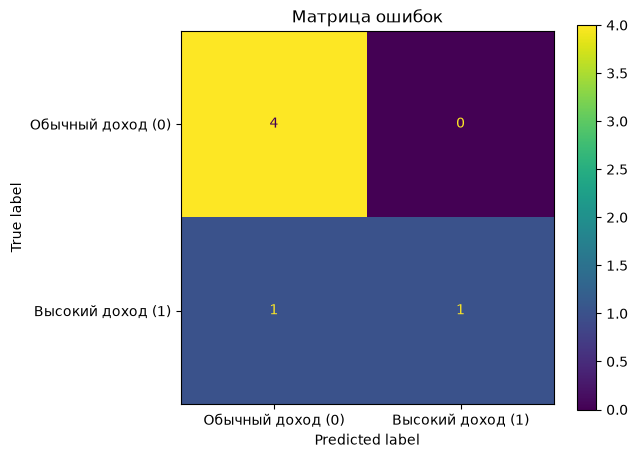

TN — верно определён обычный доход: 4
FP — обычный доход ошибочно определён как высокий: 0
FN — высокий доход ошибочно определён как обычный: 1
TP — верно определён высокий доход: 1


In [5]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Обычный доход (0)", "Высокий доход (1)"]
)
display_cm.plot(values_format="d")
plt.title("Матрица ошибок")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("TN — верно определён обычный доход:", tn)
print("FP — обычный доход ошибочно определён как высокий:", fp)
print("FN — высокий доход ошибочно определён как обычный:", fn)
print("TP — верно определён высокий доход:", tp)

## 6. Метрики классификации

In [6]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

metrics = pd.DataFrame({
    "Метрика": ["Accuracy", "Precision", "Recall", "F1"],
    "Значение": [accuracy, precision, recall, f1]
})
display(metrics.round(3))

print(f"Accuracy: {accuracy:.3f} — доля всех правильных предсказаний.")
print(f"Precision: {precision:.3f} — доля действительно высокодоходных среди предсказанных как высокодоходные.")
print(f"Recall: {recall:.3f} — доля найденных высокодоходных клиентов среди всех таких клиентов.")
print(f"F1: {f1:.3f} — баланс между Precision и Recall.")

,Метрика,Значение
0,Accuracy,0.833
1,Precision,1.000
2,Recall,0.500
3,F1,0.667


Accuracy: 0.833 — доля всех правильных предсказаний.
Precision: 1.000 — доля действительно высокодоходных среди предсказанных как высокодоходные.
Recall: 0.500 — доля найденных высокодоходных клиентов среди всех таких клиентов.
F1: 0.667 — баланс между Precision и Recall.


## 7. Интерпретация и выводы

In [7]:
print("ИНТЕРПРЕТАЦИЯ МАТРИЦЫ ОШИБОК")
print(f"TN = {tn}: модель правильно отнесла {tn} клиентов к обычному доходу.")
print(f"FP = {fp}: модель ошибочно отнесла {fp} клиентов к высокому доходу.")
print(f"FN = {fn}: модель пропустила {fn} клиентов с высоким доходом.")
print(f"TP = {tp}: модель правильно нашла {tp} клиентов с высоким доходом.")

print("\\nВЫВОД")
print(f"Accuracy модели: {accuracy:.3f}.")
print(f"Precision модели: {precision:.3f}.")
print(f"Recall модели: {recall:.3f}.")
print(f"F1 модели: {f1:.3f}.")
print("Для задачи поиска клиентов с высоким доходом важен Recall, если мы хотим пропускать как можно меньше таких клиентов.")
print("Precision также важен, чтобы не относить слишком много обычных клиентов к группе высокого дохода.")
print("Использован стандартный порог классификации 0.5.")
print("Датасет небольшой, поэтому результаты предварительные и не гарантируют хорошую работу на новых данных.")

ИНТЕРПРЕТАЦИЯ МАТРИЦЫ ОШИБОК
TN = 4: модель правильно отнесла 4 клиентов к обычному доходу.
FP = 0: модель ошибочно отнесла 0 клиентов к высокому доходу.
FN = 1: модель пропустила 1 клиентов с высоким доходом.
TP = 1: модель правильно нашла 1 клиентов с высоким доходом.
\nВЫВОД
Accuracy модели: 0.833.
Precision модели: 1.000.
Recall модели: 0.500.
F1 модели: 0.667.
Для задачи поиска клиентов с высоким доходом важен Recall, если мы хотим пропускать как можно меньше таких клиентов.
Precision также важен, чтобы не относить слишком много обычных клиентов к группе высокого дохода.
Использован стандартный порог классификации 0.5.
Датасет небольшой, поэтому результаты предварительные и не гарантируют хорошую работу на новых данных.
